# Évaluation du GNN sur MIT-BIH

Ce notebook charge des segments MIT-BIH, restaure un modèle GNN entraîné (si un checkpoint est disponible),
fait l'inférence sur un jeu de test, et produit des visualisations : matrice de confusion, t-SNE des embeddings,
et visualisation d'un graphe de battements.

Assurez-vous d'avoir installé torch, torch-geometric, wfdb, scikit-learn, matplotlib, networkx et umap-learn (ou sklearn.manifold.TSNE).

In [1]:
# Imports et helpers
import os
import sys
ROOT = os.path.abspath(os.path.join('..'))
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.manifold import TSNE

# Imports du projet
from src.train import build_mitbih_bundle, _gnn_model
from src.data.preprocessing import build_graph_sample

print('imports ok')

imports ok


In [ ]:
# Configuration utilisateur
DATA_DIR = os.path.join(ROOT, 'data', 'mitbih')
MAX_RECORDS = 0  # 0 = tous les enregistrements ; pour debug: mettre 1
WINDOW_SIZE = 12
STRIDE = 6
CHECKPOINT = os.path.join(ROOT, 'weights', 'gnn_best.pth')
DEVICE = 'cuda' if (os.environ.get('CUDA_VISIBLE_DEVICES') or False) else 'cpu'
print('cfg ok')
print('DATA_DIR =', DATA_DIR)
print('CHECKPOINT =', CHECKPOINT)

cfg ok
DATA_DIR = e:\projet\coeur\data\mitbih
CHECKPOINT = e:\projet\coeur\weights\gnn_best.pth


In [7]:
# Construire le dataset (graphes + features)
bundle = build_mitbih_bundle(data_dir=DATA_DIR, max_records=MAX_RECORDS, window_size=WINDOW_SIZE, stride=STRIDE, need_graphs=True)
features_shape = bundle.features.shape if getattr(bundle, 'features', None) is not None else None
labels_shape = bundle.labels.shape if getattr(bundle, 'labels', None) is not None else None
print('graphs:', len(bundle.graphs), 'features shape:', features_shape, 'labels shape:', labels_shape)

# Créer split simple (train/test)
from sklearn.model_selection import train_test_split
idx = np.arange(len(bundle.graphs))
train_idx, test_idx = train_test_split(idx, test_size=0.25, random_state=42, stratify=bundle.labels)
train_graphs = [bundle.graphs[i] for i in train_idx]
test_graphs = [bundle.graphs[i] for i in test_idx]
print('train graphs:', len(train_graphs), 'test graphs:', len(test_graphs))

graphs: 18693 features shape: (18693, 5) labels shape: (18693,)
train graphs: 14019 test graphs: 4674


In [ ]:
# Construire le modèle GraphSAGE et restaurer checkpoint si disponible
import torch
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device', device)

# Instantiate model + classifier matching `src/train.py`
sample_graph = bundle.graphs[0] if len(bundle.graphs) else None
if sample_graph is not None:
    in_dim = sample_graph.num_node_features
elif getattr(bundle, 'features', None) is not None:
    in_dim = bundle.features.shape[1]
else:
    raise ValueError('Impossible de déterminer in_dim: dataset vide')

model = _gnn_model(in_dim=in_dim)
classifier = torch.nn.Linear(128, 2)
model.to(device)
classifier.to(device)

if os.path.isfile(CHECKPOINT):
    ck = torch.load(CHECKPOINT, map_location=device)
    try:
        model.load_state_dict(ck['model_state'])
        classifier.load_state_dict(ck['classifier_state'])
        print('Loaded checkpoint', CHECKPOINT)
    except Exception:
        print('Checkpoint found but could not be loaded into model (format mismatch).')
else:
    print('No checkpoint found at', CHECKPOINT, '\nUsing current (random) weights for a quick inference test.')

device cuda
Loaded checkpoint e:\projet\coeur\weights\gnn_best.pth


In [9]:
# Inference sur le jeu de test
from torch_geometric.loader import DataLoader as PyGDataLoader
test_loader = PyGDataLoader(test_graphs, batch_size=32, shuffle=False)
model.eval(); classifier.eval()
y_true = []
y_pred = []
embs = []
with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(device)
        out = model(batch.x, batch.edge_index, batch.batch)
        logits = classifier(out)
        preds = torch.argmax(logits, dim=-1)
        y_true.extend(batch.y.view(-1).cpu().tolist())
        y_pred.extend(preds.cpu().tolist())
        embs.append(out.cpu().numpy())

embs = np.vstack(embs) if len(embs) else np.zeros((0,128))
print('Done inference. n_test=', len(y_true))
print(classification_report(y_true, y_pred, target_names=['normal','arrhythmia']))

Done inference. n_test= 4674
              precision    recall  f1-score   support

      normal       0.98      0.98      0.98      2682
  arrhythmia       0.98      0.97      0.97      1992

    accuracy                           0.98      4674
   macro avg       0.98      0.97      0.98      4674
weighted avg       0.98      0.98      0.98      4674



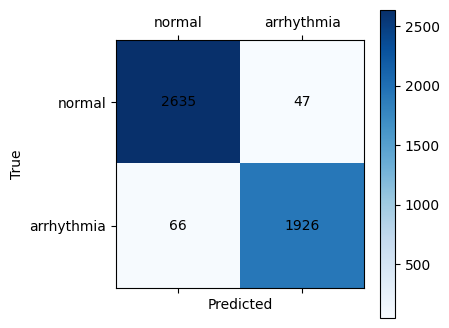

In [10]:
# Matrice de confusion
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(4,4))
cax = ax.matshow(cm, cmap='Blues')
for (i, j), val in np.ndenumerate(cm):
    ax.text(j, i, int(val), ha='center', va='center', color='black')
ax.set_xticks([0,1]); ax.set_yticks([0,1])
ax.set_xticklabels(['normal','arrhythmia']); ax.set_yticklabels(['normal','arrhythmia'])
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
fig.colorbar(cax)
plt.show()

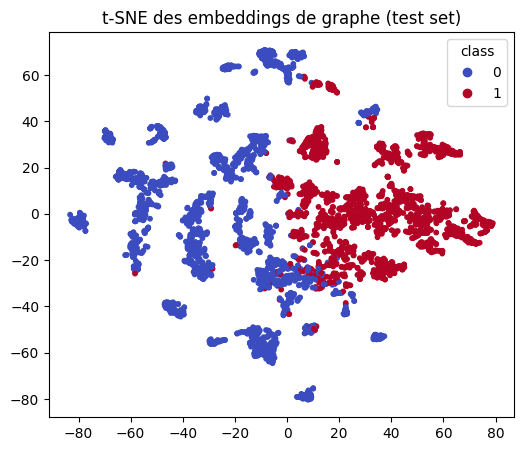

In [11]:
# t-SNE des embeddings (ou UMAP si installé)
if embs.shape[0] > 1:
    ts = TSNE(n_components=2, random_state=42)
    z = ts.fit_transform(embs)
    plt.figure(figsize=(6,5))
    scatter = plt.scatter(z[:,0], z[:,1], c=y_true, cmap='coolwarm', s=10)
    plt.title('t-SNE des embeddings de graphe (test set)')
    plt.legend(*scatter.legend_elements(), title='class')
    plt.show()
else:
    print('Pas assez d embeddings pour t-SNE')

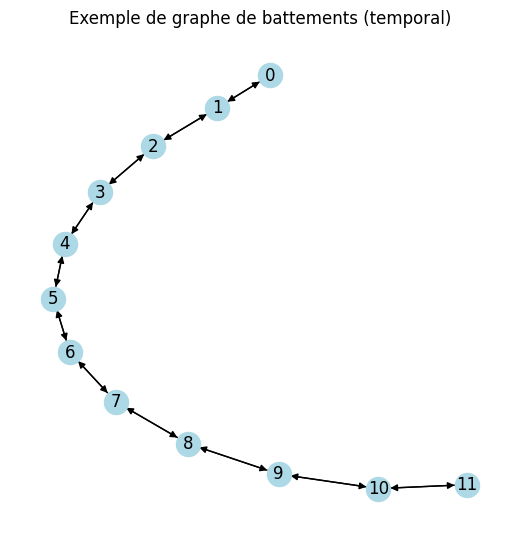

In [12]:
# Visualiser un graphe de battements exemple (premier du test)
if len(test_graphs):
    g = test_graphs[0]
    # construire NetworkX
    edge_index = g.edge_index.cpu().numpy() if hasattr(g, 'edge_index') else g['edge_index']
    G = nx.DiGraph()
    for u, v in edge_index.T:
        G.add_edge(int(u), int(v))
    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(5,5))
    nx.draw(G, pos, with_labels=True, node_color='lightblue', node_size=300)
    plt.title('Exemple de graphe de battements (temporal)')
    plt.show()
else:
    print('Aucun graphe de test à visualiser')

## Notes & next steps
- Si vous avez un checkpoint entraîné, placez-le dans weights/gnn_best.pth avec les clés model_state et classifier_state.
- Améliorations: équilibrage des classes, augmentation des features, courbes d'apprentissage enregistrées pendant l'entraînement.
- Pour des visualisations plus avancées, utilisez umap-learn pour embeddings et ajoutez des analyses d'erreurs par classe.

In [13]:
# Charger le checkpoint et faire un test rapide sur un exemple
import os
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ck_path = CHECKPOINT
if os.path.isfile(ck_path):
    ck = torch.load(ck_path, map_location=device)
    try:
        model.load_state_dict(ck['model_state'])
        classifier.load_state_dict(ck['classifier_state'])
        print('Checkpoint charge :', ck_path, ' epoch=', ck.get('epoch'), ' best_metric=', ck.get('best_metric'))
    except Exception as e:
        print('Erreur lors du chargement du checkpoint (format incompatible ?) :', e)
else:
    print('Aucun checkpoint trouve a', ck_path)

# Test rapide sur le premier graphe du jeu de test (si disponible)
if 'test_graphs' in globals() and len(test_graphs):
    g = test_graphs[0]
    model.eval(); classifier.eval()
    with torch.no_grad():
        g = g.to(device)
        batch = torch.zeros(g.x.size(0), dtype=torch.long, device=device)
        emb = model(g.x, g.edge_index, batch)
        logits = classifier(emb)
        pred = int(torch.argmax(logits, dim=-1).cpu().item())
        true = int(g.y.item())
    print('Prediction exemple -> pred:', pred, ', true:', true)
else:
    print('Pas de graphes de test disponibles pour le test rapide')

Checkpoint charge : e:\projet\coeur\weights\gnn_best.pth  epoch= 97  best_metric= 0.9752543093138715
Prediction exemple -> pred: 0 , true: 0


In [14]:
# Synthèse compacte des résultats pour le rapport
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

if 'y_true' in globals() and 'y_pred' in globals() and len(y_true) and len(y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1m = f1_score(y_true, y_pred, average='macro')
    cm = confusion_matrix(y_true, y_pred)
    print('RESULTS accuracy=', round(float(acc), 6))
    print('RESULTS f1_macro=', round(float(f1m), 6))
    print('RESULTS n_test=', len(y_true))
    print('RESULTS confusion_matrix=', cm.tolist())
else:
    print('RESULTS unavailable: y_true/y_pred absents')

if 'ck' in globals() and isinstance(ck, dict):
    print('RESULTS checkpoint_epoch=', ck.get('epoch'))
    print('RESULTS checkpoint_best_metric=', ck.get('best_metric'))
else:
    print('RESULTS checkpoint info unavailable')

RESULTS accuracy= 0.975824
RESULTS f1_macro= 0.975254
RESULTS n_test= 4674
RESULTS confusion_matrix= [[2635, 47], [66, 1926]]
RESULTS checkpoint_epoch= 97
RESULTS checkpoint_best_metric= 0.9752543093138715
